# PRCR++ : Counterfactual Evidence Fusion and Uplift Routing for Vision-Language Models
### Perception–Reasoning Counterfactual Routing: Diagnosing and Recovering Vision-Language Model Errors at Inference Time (v2)

## What your first run showed (and what this version changes)

| Finding in the v1 output | Why it capped accuracy | Fix in v2 |
|---|---|---|
| PRCR ≈ baseline (SQA 0.790 vs 0.783; MathVista 0.527 vs 0.527) and **worse on POPE** (0.867 vs 0.897, CI excludes 0) | The router moved answers without evidence that it helps | Route by **estimated uplift** of each repair, with a *do-nothing* default |
| Oracle router reached 0.897 / 0.937 / 0.743, so 4–22 points of headroom existed | Router could not find it | Uplift regression uses **all** samples and a **soft** target, so it learns from far more signal |
| 5-class diagnosis macro-F1 only 0.24–0.27; classes tiny (PERC = 17 of 900 test samples) | Hard, noisy classification with rare classes | Diagnosis is now **derived** from the estimated uplifts (no rare-class classifier) |
| V-repair (caption) and V+R were **below baseline** in every dataset (harm up to 29%) | A 2B model's own caption adds hallucinations | **No captions.** Visual repair = **high-resolution re-look + zoomed crop** (cheap, no generation) |
| Calibration temperature hit its bound (T = 6.0), `tau` = 0 | Router carried no usable confidence | Router replaced by gain regressors; no temperature hack |
| Confidence-only features ≈ full features | The probe JS-features added little | Probes are now **fused as evidence** (learned log-linear weights, including a *negative* weight for the no-image view) and a **hidden-state error probe** is added |
| ~10 s/sample (49 min per 300) | Caption + second CoT generation | About half the cost (no caption, no second generation) |

## New techniques (the novelty for the paper)
1. **Counterfactual Evidence Fusion (CEF).** Every counterfactual view (option-order permutations, paraphrase, blur, zoom, *no-image*) is treated as evidence and combined by a learned log-linear model. The weights are interpretable: a **negative weight on the no-image view** is language-prior subtraction (contrastive decoding), and the permutation average removes option-position bias. This already improves the answer *before* any routing.
2. **Hidden-state error probe.** A small probe on the VLM's last-token hidden states predicts whether the baseline answer is wrong. It is far more informative than softmax confidence in the error-detection literature, and is a router feature.
3. **Counterfactual Uplift Routing (the router).** Each repair is a *treatment*. A T-learner estimates its expected gain over the cheap fused answer, `ĝ_a(x) = E[p_a(y*) − p_CEF(y*)]`, and applies the action with the largest positive gain; otherwise it keeps the cheap answer. The **diagnosis** (perception / reasoning / mixed / none) is read off the estimated effects of the visual and reasoning repairs, rather than learned as a label.
4. **Rigorous evaluation:** pooled 5-fold cross-validation, **leave-one-dataset-out** cross-domain test, paired bootstrap CIs, accuracy-vs-intervention-rate curves against confidence gating, error-detection AUROC, and a *diagnosis-validity* test (do visually-routed samples really benefit more from the visual repair?).

## Honest notes
- This notebook was **not run on a GPU by me**. The analysis half (Part B) was tested end-to-end on synthetic data only. The extraction half (Part A) uses the same I/O code that already ran in your Kaggle output, plus new views. Run `QUICK_DEBUG=True` first.
- I cannot promise "peak" accuracy. The oracle numbers show headroom exists; whether PRCR++ captures it is decided by your run. Report whatever it produces, including negative results.
- Old caches are **not reusable** (v1 did not store the per-view probabilities). Use a fresh `WORK` cache; this version stores everything needed for Part B.

## 0. Install and configuration

In [1]:
!pip install -q -U "transformers>=4.49" accelerate datasets scikit-learn seaborn pillow tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os, sys, time, json, pickle, random, math, warnings, glob
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

WORK  = "/kaggle/working" if os.path.exists("/kaggle/working") else "./work"
CACHE = f"{WORK}/cache_v2"; RES = f"{WORK}/results_v2"
os.makedirs(CACHE, exist_ok=True); os.makedirs(RES, exist_ok=True)

CFG = dict(
    MODEL_ID    = "Qwen/Qwen2-VL-2B-Instruct",   # worked on your T4. Optional stronger backbone: "Qwen/Qwen2.5-VL-3B-Instruct"
    SEED        = 42,
    N_SQA       = 1100,    # ScienceQA (train split, image questions)
    N_POPE      = 400,     # POPE
    N_MV        = 400,     # MathVista testmini multiple-choice (max ~540 available)
    LO_MIN_PIX  = 64*28*28,  LO_MAX_PIX = 256*28*28,   # normal view
    HI_MIN_PIX  = 400*28*28, HI_MAX_PIX = 700*28*28,   # high-resolution re-look (visual repair)
    MAX_SHIFTS  = 5,           # cyclic option permutations used for position-debiasing
    COT_TOKENS  = 160,
    QUICK_DEBUG = False,
)
if CFG["QUICK_DEBUG"]:
    for k in ["N_SQA", "N_POPE", "N_MV"]: CFG[k] = 16
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
print(json.dumps(CFG, indent=1))

{
 "MODEL_ID": "Qwen/Qwen2-VL-2B-Instruct",
 "SEED": 42,
 "N_SQA": 1100,
 "N_POPE": 400,
 "N_MV": 400,
 "LO_MIN_PIX": 50176,
 "LO_MAX_PIX": 200704,
 "HI_MIN_PIX": 313600,
 "HI_MAX_PIX": 548800,
 "MAX_SHIFTS": 5,
 "COT_TOKENS": 160,
 "QUICK_DEBUG": false
}


## 1. Load the frozen VLM (two image resolutions)

In [3]:
import torch
from PIL import Image, ImageFilter
from tqdm.auto import tqdm
from transformers import AutoProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

def load_model(dtype):
    try:
        from transformers import AutoModelForImageTextToText as AutoVLM
    except Exception:
        from transformers import AutoModelForVision2Seq as AutoVLM
    return AutoVLM.from_pretrained(CFG["MODEL_ID"], torch_dtype=dtype, attn_implementation="sdpa").to(device).eval()

proc_lo = AutoProcessor.from_pretrained(CFG["MODEL_ID"], min_pixels=CFG["LO_MIN_PIX"], max_pixels=CFG["LO_MAX_PIX"])
proc_hi = AutoProcessor.from_pretrained(CFG["MODEL_ID"], min_pixels=CFG["HI_MIN_PIX"], max_pixels=CFG["HI_MAX_PIX"])
tokenizer = proc_lo.tokenizer
model = load_model(torch.float16 if device == "cuda" else torch.float32)

LETTERS = list("ABCDEFGH")
def _ids(s):
    out = set()
    for v in (s, " " + s):
        out.add(tokenizer.encode(v, add_special_tokens=False)[-1])
    return sorted(out)
CAND = [_ids(l) for l in LETTERS]

device: cuda Tesla T4


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (4 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

In [4]:
def build_inputs(img, prompt, prefix="", proc=None):
    proc = proc or proc_lo
    content = ([{"type": "image"}] if img is not None else []) + [{"type": "text", "text": prompt}]
    text = proc.apply_chat_template([{"role": "user", "content": content}], tokenize=False, add_generation_prompt=True) + prefix
    inp = proc(text=[text], images=[img] if img is not None else None, return_tensors="pt", padding=False)
    return {k: v.to(device) for k, v in inp.items()}

@torch.inference_mode()
def option_probs(img, prompt, n_opts, prefix="", proc=None, hidden=False):
    inp = build_inputs(img, prompt, prefix, proc)
    out = model(**inp, output_hidden_states=hidden)
    lp = torch.log_softmax(out.logits[0, -1].float(), -1)
    sc = torch.stack([torch.logsumexp(lp[CAND[i]], 0) for i in range(n_opts)])
    p = torch.softmax(sc, 0).cpu().numpy().astype(np.float64)
    if not np.all(np.isfinite(p)): raise FloatingPointError("non-finite probabilities")
    if not hidden: return p
    hs = out.hidden_states
    h = torch.cat([hs[-1][0, -1], hs[len(hs) // 2][0, -1]]).float().cpu().numpy().astype(np.float16)
    return p, h

@torch.inference_mode()
def gen_text(img, prompt, max_new_tokens):
    inp = build_inputs(img, prompt)
    out = model.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False)
    return proc_lo.batch_decode(out[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

def fmt_options(choices): return "\n".join(f"{LETTERS[i]}. {c}" for i, c in enumerate(choices))
def base_prompt(q, choices, style=0):
    if style == 0:
        return f"Question: {q}\nOptions:\n{fmt_options(choices)}\nAnswer with the letter of the correct option only."
    return f"Carefully consider the question below.\n{q}\nChoices:\n{fmt_options(choices)}\nReply with a single letter."
COT_SUFFIX   = "\nThink step by step in at most four short sentences, then give the final answer."
FINAL_PREFIX = "\nFinal answer (letter only): "

_toy = Image.new("RGB", (224, 224), (200, 30, 30))
try:
    print("sanity:", option_probs(_toy, base_prompt("What colour is the image?", ["red", "blue"]), 2))
except Exception as e:
    print("fp16 failed -> fp32:", repr(e)[:80]); del model; torch.cuda.empty_cache(); model = load_model(torch.float32)

sanity: [0.52341866 0.47658136]


## 2. Datasets (one pool, cross-validated; no separate hand-picked test split)
ScienceQA (reasoning + diagrams), POPE (perception / hallucination), MathVista-MC (hard reasoning). Part B uses **5-fold cross-validation over the pool** and a **leave-one-dataset-out** cross-domain test, which uses the small data far better than a fixed 300-sample split.

In [5]:
from datasets import load_dataset

def _prep_img(im):
    im = im.convert("RGB"); w, h = im.size
    if min(w, h) < 56:
        s = 56 / min(w, h); im = im.resize((max(56, int(w*s)), max(56, int(h*s))))
    return im

def load_sqa(n, seed):
    ds = load_dataset("derek-thomas/ScienceQA", split="train", streaming=True)
    ds = ds.filter(lambda x: x["image"] is not None).shuffle(seed=seed, buffer_size=3000).take(n)
    out = []
    for x in ds:
        ch = list(x["choices"])
        if not (2 <= len(ch) <= 8): continue
        q = x["question"] + (f"\nContext: {x['hint']}" if x.get("hint") else "")
        out.append(dict(img=_prep_img(x["image"]), q=q, choices=ch, label=int(x["answer"])))
    return out

def load_pope(n, seed):
    ds = load_dataset("lmms-lab/POPE", split="test"); idx = np.random.RandomState(seed).permutation(len(ds))[:n]; out = []
    for i in idx:
        x = ds[int(i)]
        out.append(dict(img=_prep_img(x["image"]), q=x["question"], choices=["Yes", "No"],
                        label=0 if str(x["answer"]).strip().lower().startswith("yes") else 1))
    return out

def load_mathvista(n, seed):
    ds = load_dataset("AI4Math/MathVista", split="testmini")
    idx = [i for i, t in enumerate(ds["question_type"]) if t == "multi_choice"]
    idx = list(np.random.RandomState(seed).permutation(idx)); out = []
    for i in idx:
        x = ds[int(i)]; ch = list(x["choices"]) if x["choices"] else []
        if not (2 <= len(ch) <= 8) or x["answer"] not in ch: continue
        im = x.get("decoded_image") or x.get("image")
        if im is None or isinstance(im, str): continue
        out.append(dict(img=_prep_img(im), q=x["question"], choices=ch, label=ch.index(x["answer"])))
        if len(out) >= n: break
    return out

DATA = {"sqa": load_sqa(CFG["N_SQA"], CFG["SEED"]), "pope": load_pope(CFG["N_POPE"], CFG["SEED"] + 1),
        "mv": load_mathvista(CFG["N_MV"], CFG["SEED"] + 2)}
for k, v in DATA.items(): print(f"{k:5s} n={len(v)}  options/question={np.mean([len(s['choices']) for s in v]):.2f}")

README.md:   0%|          | 0.00/10.3k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.16k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

... (9 outputs left out)

data/test-00001-of-00002-6a611c71596db30(…): downloading bytes:           |  0.00B            

Generating testmini split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5141 [00:00<?, ? examples/s]

sqa   n=1100  options/question=3.04
pope  n=400  options/question=2.00
mv    n=400  options/question=3.43


## 3. Extraction: counterfactual views, visual repair, reasoning repair, hidden states

| Stored view | How it is computed | Role |
|---|---|---|
| `p0` | baseline (image, question) | reference |
| `perm` | average over cyclic option orders, mapped back | removes option-position bias |
| `para` | paraphrased instruction | reasoning-side sensitivity |
| `blur`, `crop` | blurred image, centre zoom | perception-side sensitivity |
| `noimg` | question only | language prior (fused with a **negative** weight when it hurts) |
| `hi`, `hicrop` | **high-resolution** re-look, high-res zoomed crop | **visual repair** (no generation, ~0.3 s each) |
| `R` | short chain-of-thought, then the final letter | **reasoning repair** |
| `hid` | last-token hidden states (last and middle layer) | error probe |

In [6]:
def _now():
    if device == "cuda": torch.cuda.synchronize()
    return time.perf_counter()

def extract(s):
    img, q, ch = s["img"], s["q"], s["choices"]; n = len(ch); bp = base_prompt(q, ch, 0); w, h = img.size
    V = {}
    t = _now(); p0, hid = option_probs(img, bp, n, hidden=True); V["p0"] = p0; t_base = _now() - t

    t = _now()
    V["blur"]  = option_probs(img.filter(ImageFilter.GaussianBlur(radius=8)), bp, n)
    cw, chh = int(w * 0.6), int(h * 0.6); l, tp = (w - cw) // 2, (h - chh) // 2
    V["crop"]  = option_probs(img.crop((l, tp, l + cw, tp + chh)).resize((w, h)), bp, n)
    V["noimg"] = option_probs(None, bp, n)
    V["para"]  = option_probs(img, base_prompt(q, ch, 1), n)
    acc = [p0]                                   # cyclic shifts: position-debiased average
    for sft in range(1, min(n, CFG["MAX_SHIFTS"])):
        order = [(j + sft) % n for j in range(n)]
        pp = option_probs(img, base_prompt(q, [ch[o] for o in order], 0), n)
        back = np.zeros(n); back[np.array(order)] = pp; acc.append(back)
    V["perm"] = np.mean(acc, 0)
    t_cheap = _now() - t

    t = _now()                                   # visual repair: high-resolution re-look
    V["hi"] = option_probs(img, bp, n, proc=proc_hi)
    cw, chh = int(w * 0.7), int(h * 0.7); l, tp = (w - cw) // 2, (h - chh) // 2
    V["hicrop"] = option_probs(img.crop((l, tp, l + cw, tp + chh)), bp, n, proc=proc_hi)
    t_hi = _now() - t

    t = _now(); cp = bp + COT_SUFFIX              # reasoning repair
    rat = gen_text(img, cp, CFG["COT_TOKENS"]); V["R"] = option_probs(img, cp, n, prefix=rat + FINAL_PREFIX)
    t_R = _now() - t

    return dict(views={k: v.tolist() for k, v in V.items()}, hid=hid,
                meta=dict(qlen=len(q), has_ctx=int("Context:" in q), aspect=w / h, minside=min(w, h)),
                t=dict(base=t_base, cheap=t_cheap, hi=t_hi, R=t_R), rat=rat[:300])

def run_split(name, samples):
    path = f"{CACHE}/{name}.pkl"
    recs = pickle.load(open(path, "rb")) if os.path.exists(path) else []
    done = {r["idx"] for r in recs}; fails = 0
    for i, s in enumerate(tqdm(samples, desc=name)):
        if i in done: continue
        try: r = extract(s)
        except Exception as e:
            fails += 1; print("skip", i, repr(e)[:120]); continue
        r.update(ds=name, idx=i, y=int(s["label"]), n=len(s["choices"]), q=s["q"][:160].replace("\n", " "))
        recs.append(r)
        if len(recs) % 25 == 0: pickle.dump(recs, open(path, "wb"))
        if len(recs) % 50 == 0 and device == "cuda": torch.cuda.empty_cache()
    pickle.dump(recs, open(path, "wb")); print(f"{name}: {len(recs)} records ({fails} skipped)"); return recs

### 3.1 Run extraction
Resumable (saved every 25 samples). Expect roughly **4–6 s per sample on a T4** (v1 was ~10 s). Run `QUICK_DEBUG=True` first.

In [7]:
t0 = time.time()
for name in ["pope", "mv", "sqa"]:
    run_split(name, DATA[name]); print(f"elapsed {(time.time()-t0)/60:.1f} min")
try:
    del model; torch.cuda.empty_cache()
except Exception: pass
print(sorted(os.listdir(CACHE)))

pope:   0%|          | 0/400 [00:00<?, ?it/s]

pope: 400 records (0 skipped)
elapsed 14.6 min


mv:   0%|          | 0/400 [00:00<?, ?it/s]

mv: 400 records (0 skipped)
elapsed 45.2 min


sqa:   0%|          | 0/1100 [00:00<?, ?it/s]

sqa: 1100 records (0 skipped)
elapsed 121.6 min
['mv.pkl', 'pope.pkl', 'sqa.pkl']


# Part B: fusion, uplift routing, evaluation (CPU, minutes)

In [8]:
# PART-B
import os, json, pickle, glob, warnings, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
WORK  = "/kaggle/working" if os.path.exists("/kaggle/working") else "./work"
CACHE = f"{WORK}/cache_v2"; RES = f"{WORK}/results_v2"; os.makedirs(RES, exist_ok=True)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

PRETTY = {"sqa": "ScienceQA", "pope": "POPE", "mv": "MathVista-MC"}
CHEAP  = ["p0", "perm", "para", "blur", "crop", "noimg"]
FSETS  = {"F0": CHEAP, "FV": CHEAP + ["hi", "hicrop"], "FR": CHEAP + ["R"], "FVR": CHEAP + ["hi", "hicrop", "R"]}
ACTIONS = ["FV", "FR", "FVR"]
K = 8

R_ = []
for fn in sorted(glob.glob(f"{CACHE}/*.pkl")): R_ += pickle.load(open(fn, "rb"))
N = len(R_); assert N > 60, "Run Part A first."
ds   = np.array([r["ds"] for r in R_]); y = np.array([r["y"] for r in R_]); nopt = np.array([r["n"] for r in R_])
mask = np.arange(K)[None, :] < nopt[:, None]
ALLV = sorted(set(sum(FSETS.values(), [])))
PV = {v: np.zeros((N, K)) for v in ALLV}; LV = {v: np.zeros((N, K)) for v in ALLV}
for i, r in enumerate(R_):
    for v in ALLV:
        p = np.array(r["views"][v]); PV[v][i, :len(p)] = p; LV[v][i, :len(p)] = np.log(np.clip(p, 1e-6, 1))
HID  = np.stack([np.asarray(r["hid"], dtype=np.float32) for r in R_])
META = pd.DataFrame([r["meta"] for r in R_]); META["n"] = nopt
TM = {k: np.array([r["t"][k] for r in R_]) for k in ["base", "cheap", "hi", "R"]}
ar = np.arange(N)
print(pd.Series(ds).value_counts().to_string()); print("hidden dim:", HID.shape[1])

sqa     1100
mv       400
pope     400
hidden dim: 3072


## 4. Baseline accuracy of every single view (what each counterfactual alone gives)

,n,R,blur,crop,hi,hicrop,noimg,p0,para,perm,best view (oracle)
dataset,,,,,,,,,,,
ScienceQA,1100,0.744,0.670,0.684,0.742,0.706,0.615,0.746,0.745,0.765,0.895
POPE,400,0.920,0.762,0.840,0.922,0.852,0.548,0.910,0.898,0.908,0.995
MathVista-MC,400,0.572,0.470,0.505,0.575,0.502,0.390,0.562,0.542,0.560,0.808


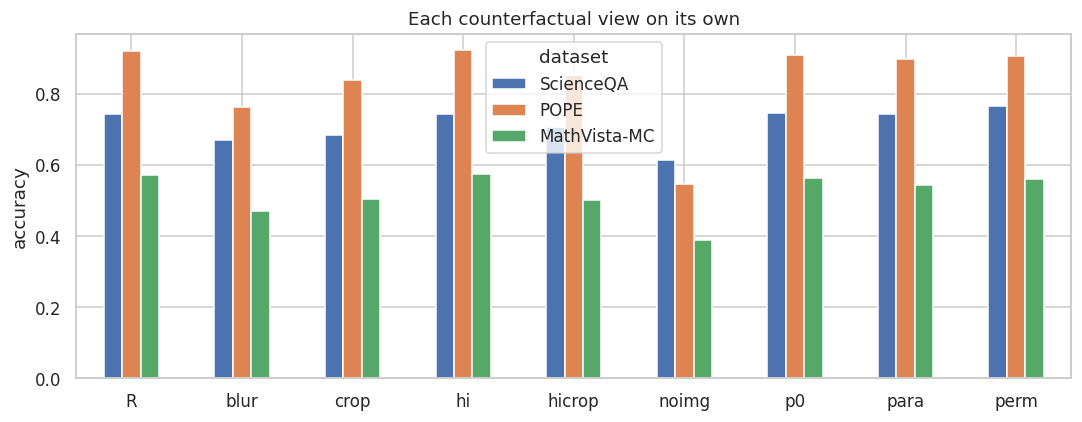

In [9]:
# PART-B
rows = []
for d in PRETTY:
    m = ds == d
    row = {"dataset": PRETTY[d], "n": int(m.sum())}
    for v in ALLV: row[v] = (PV[v][m].argmax(1) == y[m]).mean()
    row["best view (oracle)"] = np.mean([any(PV[v][i].argmax() == y[i] for v in ALLV) for i in np.where(m)[0]])
    rows.append(row)
tab_views = pd.DataFrame(rows).set_index("dataset"); display(tab_views.round(3)); tab_views.round(4).to_csv(f"{RES}/table_single_views.csv")
ax = tab_views.drop(columns=["n", "best view (oracle)"]).T.plot(kind="bar", figsize=(10, 4)); ax.set_ylabel("accuracy"); ax.set_title("Each counterfactual view on its own")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(f"{RES}/fig_single_views.png"); plt.show()

## 5. Counterfactual Evidence Fusion (CEF)
Learned log-linear combination of the view distributions:
`log p_fused(j) = Σ_m w_m · log p_m(j) + const`, fitted by maximum likelihood with a ridge pull toward "only the baseline view". A **negative `w` on `noimg`** means the model learned to subtract the language prior.

In [10]:
# PART-B
def softmax_masked(z, m):
    z = np.where(m, z, -1e9); z = z - z.max(1, keepdims=True); e = np.exp(z) * m
    return e / e.sum(1, keepdims=True)

def fit_weights(names, idx, reg=0.02):
    L = np.stack([LV[v][idx] for v in names], 1); m = mask[idx]; yy = y[idx]; n_ = len(idx); M = len(names)
    w0 = np.zeros(M); w0[0] = 1.0; rows_ = np.arange(n_)
    def f(w):
        p = softmax_masked(np.einsum("m,nmk->nk", w, L), m)
        nll = -np.log(p[rows_, yy] + 1e-12).mean() + reg * np.sum((w - w0) ** 2)
        g = (np.einsum("nk,nmk->m", p, L) - L[rows_, :, yy].sum(0)) / n_ + 2 * reg * (w - w0)
        return nll, g
    return minimize(f, w0, jac=True, method="L-BFGS-B", bounds=[(-3, 3)] * M).x

def fuse(names, w, idx):
    return softmax_masked(np.einsum("m,nmk->nk", w, np.stack([LV[v][idx] for v in names], 1)), mask[idx])

# fit on everything only for illustration of the learned weights (the evaluation below re-fits inside each CV fold)
w_demo = {k: fit_weights(FSETS[k], np.arange(N)) for k in FSETS}
wt = pd.DataFrame({k: pd.Series(w_demo[k], index=FSETS[k]) for k in FSETS}).round(3)
display(wt); wt.to_csv(f"{RES}/table_fusion_weights_all_data.csv")
for k in FSETS:
    p = fuse(FSETS[k], w_demo[k], np.arange(N)); print(k, "in-sample acc:", round((p.argmax(1) == y).mean(), 4))

,F0,FV,FR,FVR
R,NaN,NaN,0.074,0.072
blur,-0.087,-0.092,-0.079,-0.082
crop,0.011,0.005,0.003,0.004
hi,NaN,0.142,NaN,0.112
hicrop,NaN,-0.024,NaN,-0.030
noimg,0.098,0.098,0.096,0.095
p0,0.661,0.602,0.605,0.562
para,-0.064,-0.092,-0.082,-0.103
perm,0.338,0.313,0.293,0.275


F0 in-sample acc: 0.7447
FV in-sample acc: 0.7463
FR in-sample acc: 0.7547
FVR in-sample acc: 0.7589


## 6. Router features, hidden-state error probe, uplift models

In [ ]:
# PART-B
def js_v(P, Q, m):
    M_ = 0.5 * (P + Q); kl = lambda A, B: np.sum(np.where(m, A * np.log((A + 1e-12) / (B + 1e-12)), 0), 1)
    return (0.5 * kl(P, M_) + 0.5 * kl(Q, M_)) / np.log(2)

def stats(P, m, n):
    srt = np.sort(np.where(m, P, 0), 1)[:, ::-1]
    H = -np.where(m, P * np.log(P + 1e-12), 0).sum(1) / np.log(n)
    return srt[:, 0], H, srt[:, 0] - srt[:, 1]

def hidden_probe(tr, te, seed=0):
    mk = lambda: make_pipeline(StandardScaler(), PCA(min(32, len(tr) // 4), random_state=seed), LogisticRegression(C=0.05, max_iter=3000))
    tgt = (PV["p0"][tr].argmax(1) == y[tr]).astype(int)
    hp_tr = cross_val_predict(mk(), HID[tr], tgt, cv=5, method="predict_proba")[:, 1]    # out-of-fold on the training part
    hp_te = mk().fit(HID[tr], tgt).predict_proba(HID[te])[:, 1]
    return hp_tr, hp_te

def build_X(idx, pF0, hp, use_hidden=True):
    m = mask[idx]; n = nopt[idx]; cols = {}
    c, H, mg = stats(PV["p0"][idx], m, n); cols.update(c0=c, H0=H, mg0=mg)
    c, H, mg = stats(pF0, m, n);           cols.update(cF=c, HF=H, mgF=mg)
    af = pF0.argmax(1); r_ = np.arange(len(idx)); votes = []
    for v in CHEAP[1:]:
        cols["js_" + v] = js_v(PV["p0"][idx], PV[v][idx], m)
    for v in CHEAP:
        a = PV[v][idx].argmax(1); cols["ag_" + v] = (a == af).astype(float); votes.append(a)
    votes = np.stack(votes, 1); cols["vote_frac"] = np.mean(votes == af[:, None], 1)
    cols["vote_nuniq"] = np.array([len(set(v)) for v in votes], dtype=float)
    cols["noimg_support"] = PV["noimg"][idx][r_, af]
    cols["perm_gap"] = js_v(PV["p0"][idx], PV["perm"][idx], m)
    cols["n_opts"] = n.astype(float); cols["log_qlen"] = np.log1p(META.qlen.values[idx]); cols["has_ctx"] = META.has_ctx.values[idx].astype(float)
    cols["aspect"] = META.aspect.values[idx]; cols["log_minside"] = np.log(META.minside.values[idx])
    if use_hidden: cols["hid_probe"] = hp
    return pd.DataFrame(cols)

def make_reg(seed=0):
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.06, max_iter=120, min_samples_leaf=25, l2_regularization=1.0, random_state=seed)

LAMS = np.linspace(0.0, 0.25, 11)
def decide(G, lam):                       # G: dict action -> gain estimate
    A = np.stack([G[a] for a in ACTIONS], 1); best = A.argmax(1); gmax = A.max(1)
    return np.where(gmax > lam, best, -1), gmax

## 7. Cross-validated evaluation of PRCR++
`run_protocol` trains **inside each fold only** the fusion weights, the hidden probe and the uplift models, then predicts the held-out fold. `lam` (the minimum expected gain required to intervene) is chosen on the *training fold* via nested out-of-fold predictions.

In [ ]:
# PART-B
def run_protocol(folds, fsets=None, use_hidden=True, seed=0, verbose=False):
    fs = fsets or FSETS
    out = dict(pred={k: np.full(N, -1) for k in fs}, conf0=np.zeros(N), action=np.full(N, -1), gmax=np.zeros(N),
               ghat={a: np.zeros(N) for a in ACTIONS}, hp=np.zeros(N), lam=np.zeros(N), perm_pred=np.full(N, -1), weights=[])
    for fi, (tr, te) in enumerate(folds):
        tr, te = np.asarray(tr), np.asarray(te)
        W = {k: fit_weights(fs[k], tr) for k in fs}; out["weights"].append({k: W[k] for k in fs})
        Ftr = {k: fuse(fs[k], W[k], tr) for k in fs}; Fte = {k: fuse(fs[k], W[k], te) for k in fs}
        for k in fs: out["pred"][k][te] = Fte[k].argmax(1)
        out["conf0"][te] = Fte["F0"].max(1)
        if use_hidden: hp_tr, hp_te = hidden_probe(tr, te, seed)
        else: hp_tr = hp_te = None
        Xtr = build_X(tr, Ftr["F0"], hp_tr, use_hidden); Xte = build_X(te, Fte["F0"], hp_te, use_hidden)
        if use_hidden: out["hp"][te] = hp_te
        rtr, rte = np.arange(len(tr)), np.arange(len(te))
        Gtr, Gte = {}, {}
        for a in ACTIONS:
            gt = Ftr[a][rtr, y[tr]] - Ftr["F0"][rtr, y[tr]]               # soft gain target
            Gte[a] = make_reg(seed).fit(Xtr, gt).predict(Xte)
            Gtr[a] = cross_val_predict(make_reg(seed), Xtr, gt, cv=4)    # nested out-of-fold estimates for choosing lam
        okF = {k: (Ftr[k].argmax(1) == y[tr]) for k in fs}; best_lam, best_acc = 0.0, -1
        for lam in LAMS:
            act, _ = decide(Gtr, lam); ok = okF["F0"].copy()
            for j, a in enumerate(ACTIONS): ok = np.where(act == j, okF[a], ok)
            if ok.mean() > best_acc + 1e-9: best_acc, best_lam = ok.mean(), lam
        act, gmax = decide(Gte, best_lam)
        out["action"][te] = act; out["gmax"][te] = gmax; out["lam"][te] = best_lam
        for a in ACTIONS: out["ghat"][a][te] = Gte[a]
        if verbose: print(f"fold {fi}: lam={best_lam:.3f} intervention={np.mean(act >= 0):.2%}")
    out["perm_pred"] = PV["perm"].argmax(1)
    return out

def pooled_folds(seed=0, n_splits=5):
    return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros(N), ds))
def lodo_folds():
    return [(np.where(ds != d)[0], np.where(ds == d)[0]) for d in PRETTY if (ds == d).any()]

OOF = run_protocol(pooled_folds(0), verbose=True)
print("pooled CV done")

fold 0: lam=0.000 intervention=92.63%
fold 1: lam=0.000 intervention=95.00%
fold 2: lam=0.000 intervention=95.00%
fold 3: lam=0.000 intervention=90.26%
fold 4: lam=0.000 intervention=92.11%
pooled CV done


## 8. Main results (pooled 5-fold cross-validation, out-of-fold predictions)
Methods: baseline VLM · position-debiased (perm only) · **CEF** (fused cheap views) · always visual / reasoning / both repair · confidence-gated (matched intervention rate) · **PRCR++** · oracle.

In [ ]:
# PART-B
def correct(pred): return pred == y
def method_table(O, label="pooled CV"):
    base_ok = correct(PV["p0"].argmax(1)); act = O["action"]
    ok = {"Baseline VLM": base_ok, "Position-debiased only (perm)": correct(O["perm_pred"]), "CEF (fused cheap views)": correct(O["pred"]["F0"]),
          "Always visual repair (CEF+hi-res)": correct(O["pred"]["FV"]), "Always reasoning repair (CEF+CoT)": correct(O["pred"]["FR"]),
          "Always both repairs": correct(O["pred"]["FVR"])}
    # PRCR++ routed answer
    routed = ok["CEF (fused cheap views)"].copy()
    for j, a in enumerate(ACTIONS): routed = np.where(act == j, correct(O["pred"][a]), routed)
    ok["PRCR++ (ours)"] = routed
    rate = np.mean(act >= 0); thr = np.quantile(O["conf0"], rate) if rate > 0 else -1
    g = O["conf0"] < thr
    ok["Conf-gated both repairs (matched rate)"] = np.where(g, correct(O["pred"]["FVR"]), ok["CEF (fused cheap views)"])
    ok["Oracle router (upper bound)"] = np.any(np.stack([correct(O["pred"][k]) for k in FSETS], 1), 1)
    cheap_t = TM["base"] + TM["cheap"]
    cost = {"Baseline VLM": TM["base"], "Position-debiased only (perm)": cheap_t, "CEF (fused cheap views)": cheap_t,
            "Always visual repair (CEF+hi-res)": cheap_t + TM["hi"], "Always reasoning repair (CEF+CoT)": cheap_t + TM["R"],
            "Always both repairs": cheap_t + TM["hi"] + TM["R"],
            "PRCR++ (ours)": cheap_t + np.select([act == 0, act == 1, act == 2], [TM["hi"], TM["R"], TM["hi"] + TM["R"]], 0.0),
            "Conf-gated both repairs (matched rate)": cheap_t + g * (TM["hi"] + TM["R"])}
    acc = pd.DataFrame({k: {PRETTY[d]: v[ds == d].mean() for d in PRETTY if (ds == d).any()} | {"All (pooled)": v.mean()} for k, v in ok.items()}).T
    lat = pd.Series({k: np.mean(c) for k, c in cost.items()}, name="latency_s")
    fix = pd.Series({k: v[~base_ok].mean() for k, v in ok.items()}, name="fix_rate"); harm = pd.Series({k: (~v)[base_ok].mean() for k, v in ok.items()}, name="harm_rate")
    return acc.join(lat).join(fix).join(harm), ok, routed

main, OK, ROUTED = method_table(OOF)
display(main.round(3)); main.round(4).to_csv(f"{RES}/table_main_pooled_cv.csv")
print(f"PRCR++ intervention rate: {np.mean(OOF['action'] >= 0):.1%} | action mix:", pd.Series(np.array(['none'] + ACTIONS, dtype=object)[OOF['action'] + 1]).value_counts().to_dict())

,ScienceQA,POPE,MathVista-MC,All (pooled),latency_s,fix_rate,harm_rate
Baseline VLM,0.746,0.910,0.562,0.742,0.162,0.000,0.000
Position-debiased only (perm),0.765,0.908,0.560,0.752,1.001,0.161,0.043
CEF (fused cheap views),0.752,0.918,0.558,0.746,1.001,0.059,0.016
Always visual repair (CEF+hi-res),0.747,0.920,0.565,0.745,1.724,0.059,0.016
Always reasoning repair (CEF+CoT),0.755,0.918,0.595,0.755,3.113,0.143,0.032
Always both repairs,0.755,0.922,0.602,0.758,3.837,0.147,0.029
PRCR++ (ours),0.757,0.922,0.592,0.757,3.140,0.127,0.023
Conf-gated both repairs (matched rate),0.755,0.922,0.602,0.758,3.712,0.147,0.029
Oracle router (upper bound),0.783,0.930,0.628,0.781,NaN,0.171,0.007


PRCR++ intervention rate: 93.0% | action mix: {'FVR': 775, 'FR': 541, 'FV': 451, 'none': 133}


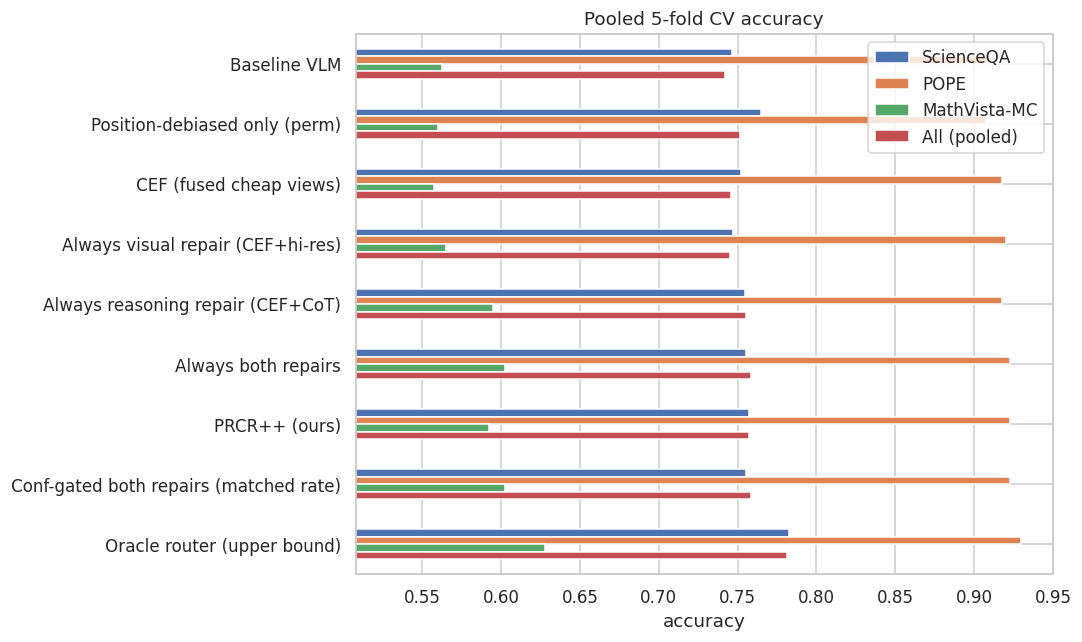

In [ ]:
# PART-B
plot = main.drop(columns=["latency_s", "fix_rate", "harm_rate"])
ax = plot.plot(kind="barh", figsize=(10, 6)); ax.invert_yaxis(); ax.set_xlabel("accuracy"); ax.set_title("Pooled 5-fold CV accuracy")
ax.set_xlim(max(0, plot.min().min() - 0.05), min(1, plot.max().max() + 0.02)); plt.tight_layout(); plt.savefig(f"{RES}/fig_main_pooled_cv.png"); plt.show()

### 8.1 Cross-domain test: leave-one-dataset-out (train on two datasets, test on the third)

In [ ]:
# PART-B
OOF_L = run_protocol(lodo_folds(), verbose=True)
main_l, OK_L, ROUTED_L = method_table(OOF_L)
display(main_l.round(3)); main_l.round(4).to_csv(f"{RES}/table_main_lodo.csv")

fold 0: lam=0.000 intervention=83.27%
fold 1: lam=0.000 intervention=90.00%
fold 2: lam=0.050 intervention=0.00%


,ScienceQA,POPE,MathVista-MC,All (pooled),latency_s,fix_rate,harm_rate
Baseline VLM,0.746,0.910,0.562,0.742,0.162,0.000,0.000
Position-debiased only (perm),0.765,0.908,0.560,0.752,1.001,0.161,0.043
CEF (fused cheap views),0.750,0.910,0.555,0.743,1.001,0.041,0.013
Always visual repair (CEF+hi-res),0.753,0.912,0.565,0.747,1.724,0.059,0.014
Always reasoning repair (CEF+CoT),0.755,0.915,0.598,0.755,3.113,0.163,0.039
Always both repairs,0.755,0.920,0.602,0.758,3.837,0.167,0.037
PRCR++ (ours),0.758,0.912,0.555,0.748,2.095,0.092,0.024
Conf-gated both repairs (matched rate),0.755,0.920,0.602,0.758,3.272,0.167,0.037
Oracle router (upper bound),0.798,0.925,0.625,0.788,NaN,0.196,0.006


## 9. Statistical reliability (paired bootstrap, 2,000 resamples)

In [ ]:
# PART-B
def boot(a, b, B=2000, seed=0, groups=None):
    rng = np.random.RandomState(seed); idx = np.arange(len(a)) if groups is None else groups; n_ = len(idx); d = []
    for _ in range(B):
        ix = idx[rng.randint(0, n_, n_)]; d.append(a[ix].mean() - b[ix].mean())
    return np.mean(d), np.percentile(d, 2.5), np.percentile(d, 97.5)

rows = []
for proto, OKx in [("pooled CV", OK), ("leave-one-dataset-out", OK_L)]:
    for ref in ["Baseline VLM", "CEF (fused cheap views)", "Conf-gated both repairs (matched rate)"]:
        for d in list(PRETTY) + ["all"]:
            g = np.where(ds == d)[0] if d != "all" else None
            if g is not None and len(g) == 0: continue
            m_, lo, hi = boot(OKx["PRCR++ (ours)"].astype(float), OKx[ref].astype(float), groups=g)
            rows.append(dict(protocol=proto, dataset=PRETTY.get(d, "All"), vs=ref, gain=m_, ci_low=lo, ci_high=hi, significant=(lo > 0 or hi < 0)))
boot_tab = pd.DataFrame(rows); display(boot_tab.round(4)); boot_tab.round(4).to_csv(f"{RES}/table_bootstrap.csv", index=False)

,protocol,dataset,vs,gain,ci_low,ci_high,significant
0,pooled CV,ScienceQA,Baseline VLM,0.0108,-0.0018,0.0227,False
1,pooled CV,POPE,Baseline VLM,0.0124,0.0000,0.0275,False
2,pooled CV,MathVista-MC,Baseline VLM,0.0300,0.0000,0.0600,False
3,pooled CV,All,Baseline VLM,0.0154,0.0058,0.0253,True
4,pooled CV,ScienceQA,CEF (fused cheap views),0.0056,-0.0055,0.0173,False
5,pooled CV,POPE,CEF (fused cheap views),0.0050,-0.0050,0.0150,False
6,pooled CV,MathVista-MC,CEF (fused cheap views),0.0350,0.0075,0.0625,True
7,pooled CV,All,CEF (fused cheap views),0.0117,0.0026,0.0211,True
8,pooled CV,ScienceQA,Conf-gated both repairs (matched rate),0.0019,-0.0055,0.0100,False
9,pooled CV,POPE,Conf-gated both repairs (matched rate),0.0000,0.0000,0.0000,False


## 10. Is the error predictable? (AUROC of detecting a wrong baseline answer)

In [ ]:
# PART-B
wrong = (~OK["Baseline VLM"]).astype(int)
sc = {"Baseline confidence (1 - c0)": 1 - PV["p0"].max(1), "Fused-CEF confidence (1 - cF)": 1 - OOF["conf0"],
      "Hidden-state probe (1 - P(correct))": 1 - OOF["hp"], "Max estimated uplift (gmax)": OOF["gmax"]}
rows = []
for nm, s in sc.items():
    r = {"score": nm}
    for d in list(PRETTY) + ["all"]:
        m = (ds == d) if d != "all" else np.ones(N, bool)
        r[PRETTY.get(d, "All")] = roc_auc_score(wrong[m], s[m]) if 0 < wrong[m].sum() < m.sum() else np.nan
    rows.append(r)
auc = pd.DataFrame(rows).set_index("score"); display(auc.round(3)); auc.round(4).to_csv(f"{RES}/table_error_auroc.csv")

,ScienceQA,POPE,MathVista-MC,All
score,,,,
Baseline confidence (1 - c0),0.841,0.789,0.826,0.860
Fused-CEF confidence (1 - cF),0.849,0.805,0.829,0.867
Hidden-state probe (1 - P(correct)),0.841,0.849,0.834,0.863
Max estimated uplift (gmax),0.700,0.717,0.621,0.703


## 11. Accuracy vs. intervention rate (Pareto): uplift routing vs. confidence gating vs. random

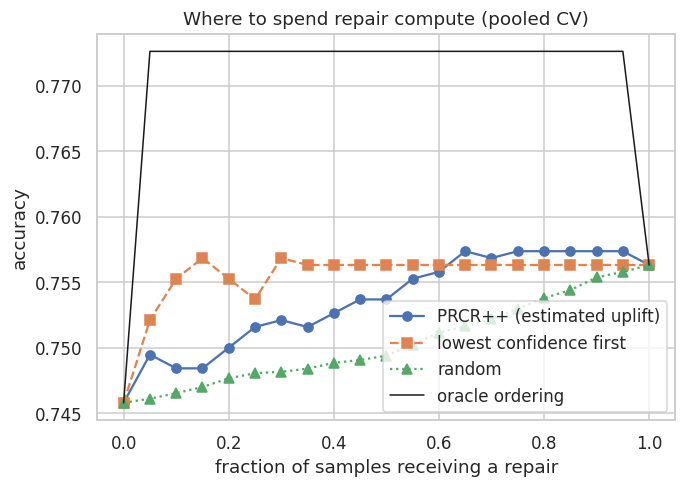

In [ ]:
# PART-B
def curve(score, rates, applied_ok, base_ok_):
    order = np.argsort(-score); accs = []
    for r in rates:
        k = int(round(r * N)); sel = np.zeros(N, bool); sel[order[:k]] = True
        accs.append(np.where(sel, applied_ok, base_ok_).mean())
    return np.array(accs)

rates = np.linspace(0, 1, 21); cef_ok = OK["CEF (fused cheap views)"]
best_action = np.argmax(np.stack([OOF["ghat"][a] for a in ACTIONS], 1), 1)
applied_ok = np.select([best_action == 0, best_action == 1, best_action == 2], [correct(OOF["pred"][a]) for a in ACTIONS], cef_ok)
oracle_gain = (applied_ok.astype(int) - cef_ok.astype(int))
rng = np.random.RandomState(0)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.plot(rates, curve(OOF["gmax"], rates, applied_ok, cef_ok), "o-", label="PRCR++ (estimated uplift)")
ax.plot(rates, curve(1 - OOF["conf0"], rates, applied_ok, cef_ok), "s--", label="lowest confidence first")
ax.plot(rates, np.mean([curve(rng.rand(N), rates, applied_ok, cef_ok) for _ in range(20)], 0), "^:", label="random")
ax.plot(rates, curve(oracle_gain + 1e-3 * rng.rand(N), rates, applied_ok, cef_ok), "k-", lw=1, label="oracle ordering")
ax.set_xlabel("fraction of samples receiving a repair"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("Where to spend repair compute (pooled CV)")
plt.tight_layout(); plt.savefig(f"{RES}/fig_pareto_intervention.png"); plt.show()

## 12. Diagnosis from uplift, and a validity test
The diagnosis is read off the estimated effects: **PERC** if the visual repair has the largest positive estimated gain, **REAS** if the reasoning repair does, **MIXED** if both together, **NONE** otherwise. *Validity test:* samples diagnosed as PERC should gain more from the visual repair than from the reasoning repair, and vice versa.

,visual repair,reasoning repair,both repairs,n
PERC,-0.002,0.007,0.009,451
REAS,-0.002,0.020,0.022,541
MIXED,0.003,0.010,0.015,775
NONE,-0.008,-0.030,-0.030,133


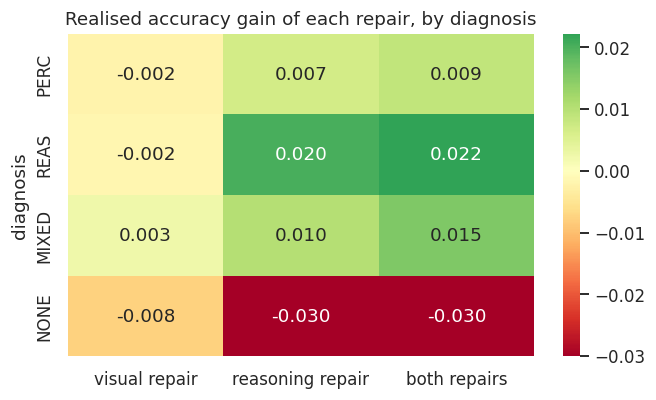

diagnosis  MIXED  NONE  PERC  REAS
dataset                           
mv           188    26    68   118
pope         173    15   146    66
sqa          414    92   237   357


In [ ]:
# PART-B
DIAG = np.array(["NONE", "PERC", "REAS", "MIXED"], dtype=object)[OOF["action"] + 1]
real = {"visual repair": correct(OOF["pred"]["FV"]).astype(float) - cef_ok, "reasoning repair": correct(OOF["pred"]["FR"]).astype(float) - cef_ok,
        "both repairs": correct(OOF["pred"]["FVR"]).astype(float) - cef_ok}
val = pd.DataFrame({k: pd.Series(v).groupby(DIAG).mean() for k, v in real.items()}).reindex(["PERC", "REAS", "MIXED", "NONE"])
val["n"] = pd.Series(DIAG).value_counts().reindex(val.index)
display(val.round(3)); val.round(4).to_csv(f"{RES}/table_diagnosis_validity.csv")
fig, ax = plt.subplots(figsize=(6.2, 3.8)); sns.heatmap(val.drop(columns="n").astype(float), annot=True, fmt=".3f", cmap="RdYlGn", center=0, ax=ax)
ax.set_title("Realised accuracy gain of each repair, by diagnosis"); ax.set_ylabel("diagnosis"); plt.tight_layout(); plt.savefig(f"{RES}/fig_diagnosis_validity.png"); plt.show()
print(pd.crosstab(pd.Series(ds, name="dataset"), pd.Series(DIAG, name="diagnosis")))

## 13. Ablations (each removes one ingredient; pooled 5-fold CV)

In [ ]:
# PART-B
def acc_of(O):
    _, okx, routed = method_table(O); return routed.mean(), {PRETTY[d]: routed[ds == d].mean() for d in PRETTY if (ds == d).any()}

def sets_without(drop):
    return {k: [v for v in names if v not in drop] for k, names in FSETS.items()}

variants = {"Full PRCR++": dict(), "No hidden-state probe": dict(use_hidden=False), "No no-image view": dict(fsets=sets_without({"noimg"})),
            "No permutation debiasing": dict(fsets=sets_without({"perm"})), "No blur/crop probes": dict(fsets=sets_without({"blur", "crop"})),
            "No high-res visual repair": dict(fsets={**FSETS, "FV": FSETS["F0"], "FVR": FSETS["F0"] + ["R"]})}
rows = []
for nm, kw in variants.items():
    O = run_protocol(pooled_folds(0), **kw); a, per = acc_of(O); rows.append({"variant": nm, "pooled acc": a, **per, "intervention rate": np.mean(O["action"] >= 0)})
abl = pd.DataFrame(rows).set_index("variant"); display(abl.round(3)); abl.round(4).to_csv(f"{RES}/table_ablation.csv")

,pooled acc,ScienceQA,POPE,MathVista-MC,intervention rate
variant,,,,,
Full PRCR++,0.757,0.757,0.922,0.592,0.930
No hidden-state probe,0.756,0.755,0.922,0.595,0.926
No no-image view,0.753,0.755,0.920,0.582,0.936
No permutation debiasing,0.753,0.753,0.922,0.582,0.958
No blur/crop probes,0.754,0.751,0.920,0.598,0.912
No high-res visual repair,0.753,0.754,0.918,0.585,0.693


## 14. Learned fusion weights across folds (interpretability)

In [ ]:
# PART-B
rows = {}
for k in ["F0", "FVR"]:
    arr = np.array([w[k] for w in OOF["weights"]]); rows[k + " mean"] = pd.Series(arr.mean(0), index=FSETS[k]); rows[k + " std"] = pd.Series(arr.std(0), index=FSETS[k])
wtab = pd.DataFrame(rows).round(3); display(wtab); wtab.to_csv(f"{RES}/table_fusion_weights_cv.csv")

,F0 mean,F0 std,FVR mean,FVR std
R,NaN,NaN,0.072,0.008
blur,-0.087,0.025,-0.082,0.027
crop,0.011,0.017,0.004,0.017
hi,NaN,NaN,0.112,0.036
hicrop,NaN,NaN,-0.030,0.022
noimg,0.098,0.022,0.094,0.022
p0,0.663,0.036,0.563,0.024
para,-0.064,0.022,-0.103,0.028
perm,0.338,0.027,0.274,0.032


## 15. Qualitative cases and export

In [ ]:
# PART-B
base_ok_ = OK["Baseline VLM"]; fixed = np.where(ROUTED & ~base_ok_)[0]; broken = np.where(~ROUTED & base_ok_)[0]
print(f"routed answer fixes {len(fixed)} baseline errors and breaks {len(broken)} correct answers (pooled CV)")
for i in fixed[:4]:
    print(f"- [{ds[i]}] {R_[i]['q'][:120]} | gold={y[i]} base={PV['p0'][i].argmax()} -> routed ({DIAG[i]}), est. gain={OOF['gmax'][i]:.2f}")

routed answer fixes 62 baseline errors and breaks 33 correct answers (pooled CV)
- [mv] As shown in the figure, given that points A, B, and C are on ⊙O, ∠AOB = 100.0, then the degree of ∠ACB is () | gold=0 base=1 -> routed (MIXED), est. gain=0.00
- [mv] Is Crimson less than Gray? | gold=1 base=0 -> routed (MIXED), est. gain=0.03
- [mv] As shown in the figure, points A, B, and C are on ⊙O, if ∠C = 35.0, then ∠AOB = () | gold=3 base=2 -> routed (REAS), est. gain=0.03
- [mv] 如图，若DE是△ABC的中位线，△ADE的周长为1，则△ABC的周长为（） | gold=1 base=2 -> routed (REAS), est. gain=0.01


In [ ]:
# PART-B
def tex(df_, name, cap, label):
    try: open(f"{RES}/{name}.tex", "w").write(df_.to_latex(float_format="%.3f", caption=cap, label=label, escape=True)); print("wrote", name)
    except Exception as e: print("latex skipped:", repr(e)[:80])
tex(main, "tab_main_pooled", "PRCR++ and baselines (pooled 5-fold CV, out-of-fold).", "tab:main_pooled")
tex(main_l, "tab_main_lodo", "Cross-domain leave-one-dataset-out evaluation.", "tab:main_lodo")
tex(abl, "tab_ablation", "Ablation of PRCR++ components.", "tab:ablation")
tex(auc, "tab_auroc", "AUROC for detecting wrong baseline answers.", "tab:auroc")
tex(val, "tab_validity", "Diagnosis validity: realised gain of each repair by diagnosis.", "tab:validity")
json.dump({"n": int(N), "per_dataset": {PRETTY[d]: int((ds == d).sum()) for d in PRETTY},
           "pooled_main": main.round(4).to_dict()}, open(f"{RES}/summary.json", "w"), indent=1, default=float)
with zipfile.ZipFile(f"{WORK}/prcrpp_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{RES}/*"): z.write(f, os.path.basename(f))
print("saved", f"{WORK}/prcrpp_results.zip"); print(sorted(os.listdir(RES)))

wrote tab_main_pooled
wrote tab_main_lodo
wrote tab_ablation
wrote tab_auroc
wrote tab_validity
saved /kaggle/working/prcrpp_results.zip
['fig_diagnosis_validity.png', 'fig_main_pooled_cv.png', 'fig_pareto_intervention.png', 'fig_single_views.png', 'summary.json', 'tab_ablation.tex', 'tab_auroc.tex', 'tab_main_lodo.tex', 'tab_main_pooled.tex', 'tab_validity.tex', 'table_ablation.csv', 'table_bootstrap.csv', 'table_diagnosis_validity.csv', 'table_error_auroc.csv', 'table_fusion_weights_all_data.csv', 'table_fusion_weights_cv.csv', 'table_main_lodo.csv', 'table_main_pooled_cv.csv', 'table_single_views.csv']


## 16. Writing it up
- **Main claim to test:** PRCR++ ≥ CEF ≥ baseline in accuracy, with PRCR++ reaching (or exceeding) *Always both repairs* accuracy at a fraction of the latency, and a positive gain in the leave-one-dataset-out table.
- **Mechanism evidence:** `table_fusion_weights_cv` (sign of the no-image weight), `table_error_auroc` (hidden probe vs softmax confidence), `fig_pareto_intervention` (uplift ordering vs confidence ordering), `table_diagnosis_validity` and `fig_diagnosis_validity`.
- **If a gain is not significant** (`table_bootstrap`), say so. A valid negative result on a 2B backbone is still publishable evidence. Consider the stronger backbone (`Qwen/Qwen2.5-VL-3B-Instruct`) or more samples (`N_*`) before drawing conclusions.
- **Limitations:** gain estimates are trained on soft targets from this backbone's own repairs; all questions are scored as multiple choice; labels are operational, not human-annotated; one backbone and three datasets.